# RAG Assignment: Baseline vs. Re-Ranking

**Course:** CL3410 Language Models and Agents · Module 7 (RAG) · **Due:** 19 Oct 2026

This notebook implements two retrieval workflows over the **exact same chunked corpus** of a single PDF and compares them:

| | Pipeline 1 (baseline) | Pipeline 2 (re-ranking) |
|---|---|---|
| Retrieve | bi-encoder + FAISS inner product, **top 10** | the **same** top 10 from Pipeline 1 |
| Re-rank | none | cross-encoder scores all 10 (query, chunk) pairs, re-sorted descending |
| To the LLM | top 3 → **Answer 1** | top 3 → **Answer 2** (identical prompt structure) |

```
 OFFLINE:  PDF -> extract & clean -> structure-aware chunks (frozen, hashed) -> bi-encoder -> FAISS IndexFlatIP
 ONLINE :  query -> bi-encoder -> FAISS top-10 --+--> top-3 ---------------------------> prompt -> LLM -> Answer 1
                                                 |
                                                 +--> cross-encoder x 10 -> sort -> top-3 -> prompt -> LLM -> Answer 2
```

**How to run:** create the venv from `requirements.txt`, put keys in `.env` (see `.env.example`), then *Restart kernel and Run All*.
Sections are added stage by stage: setup → document → chunking → index → retrieval/re-ranking → generation → queries → results → failure analysis → latency & scaling → summary.

## 1. Setup

Imports, a single `CONFIG` dict (every tunable lives here), seeds, and the compute device.
Model weights are cached **inside the project** (`.cache/huggingface`, git-ignored) so nothing is written outside the repo folder.

In [1]:
import os, time, json, hashlib, random, platform, statistics, subprocess, re, collections, unicodedata
from pathlib import Path

ROOT = Path.cwd()
# Keep Hugging Face downloads inside the project folder (set before importing sentence-transformers).
os.environ["HF_HOME"] = str(ROOT / ".cache" / "huggingface")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import torch
import faiss
import pymupdf
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers.utils import logging
logging.set_verbosity_error()                 # we only count tokens with the tokenizer, so its length warning is not needed
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")                    # API keys come from .env / environment variables, never from the code

# Every tunable parameter in one place. After the query set is frozen (Stage 6) none of these may change.
CONFIG = {
    "pdf_path": "data/netrunner_comprehensive_rules_v26.03.pdf",
    "doc": {                                  # the single source document; its SHA-256 is checked in Section 2
        "title": "Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)",
        "short": "Netrunner CR v26.03",
        "url": "https://access.nullsignal.games/CompRules/Null_Signal_Games_Netrunner_Comprehensive_Rules_v26.03.pdf",
        "sha256": "ffd36071034aeae240cb319b13be1dae1d265c4598b44fbbfb90c86297a4523e",
        "accessed": "2026-10-12",
    },
    "bi_encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "cross_encoder": "cross-encoder/ms-marco-MiniLM-L-6-v2",
    "llm_provider": None,                     # gemini | anthropic | ollama (chosen in Stage 5)
    "llm_model": None,                        # exact model id (chosen in Stage 5)
    "temperature": 0.0,
    "max_output_tokens": 400,
    "chunk_max_tokens": 220,                  # counted with the bi-encoder tokenizer, header included (its limit is 256)
    "chunk_overlap_tokens": 40,
    "k_retrieve": 10,                         # Pipeline 1 retrieves 10 chunks ...
    "k_final": 3,                             # ... and both pipelines give 3 to the LLM
    "latency_warmup": 3,
    "latency_repeats": 20,
    "seed": 42,
    "device": None,                           # chosen by the benchmark in 1.3, then fixed for all later timings
}

random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"]); torch.manual_seed(CONFIG["seed"])

for folder in ["data", "queries", "artifacts/results", "artifacts/figures", "report"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/hritikranjan/Desktop/ Folder/SEM 3/LMA/A1_RAG/RAG-BASELINE-VS-RERANKING


### 1.1 Environment record

Latency numbers depend on hardware and library versions, so they are recorded once here.

In [2]:
ENV_INFO = {
    "python": platform.python_version(),
    "machine": platform.platform(),
    "cpu": subprocess.getoutput("sysctl -n machdep.cpu.brand_string"),          # macOS
    "ram_gb": round(int(subprocess.getoutput("sysctl -n hw.memsize")) / 2**30),
    "torch": torch.__version__,
    "sentence_transformers": sentence_transformers.__version__,
    "faiss": faiss.__version__,
    "pymupdf": pymupdf.__version__,
    "mps_available": torch.backends.mps.is_available(),
    "cuda_available": torch.cuda.is_available(),
}
pd.Series(ENV_INFO, name="value").to_frame()

,value
python,3.12.13
machine,macOS-27.0-arm64-arm-64bit
cpu,Apple M4
ram_gb,24
torch,2.14.1
sentence_transformers,6.1.0
faiss,1.15.1
pymupdf,1.28.2
mps_available,True
cuda_available,False


### 1.2 Model smoke test

Both models are loaded and tried once.
- The bi-encoder **silently cuts its input at `max_seq_length` tokens** (256 for all-MiniLM-L6-v2). This is why chunks must stay below 256 tokens (Section 3).
- The cross-encoder returns a raw **logit** (any real number) for each (query, passage) pair, not a probability.

In [3]:
bi_encoder = SentenceTransformer(CONFIG["bi_encoder"], device="cpu")
cross_encoder = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device="cpu")
print("bi-encoder: embedding size", bi_encoder.get_embedding_dimension(), "| max_seq_length", bi_encoder.max_seq_length)

# bi-encoder: normalised vectors, so the inner product equals the cosine similarity
vectors = bi_encoder.encode(["a quick test sentence", "a quick test sentence"], normalize_embeddings=True)
print("vector length (norm):", float(np.linalg.norm(vectors[0])), "| cosine of identical sentences:", float(vectors[0] @ vectors[1]))

# cross-encoder: one score per (query, passage) pair
pairs = [("what is the capital of france", "Paris is the capital and largest city of France."),
         ("what is the capital of france", "Bananas are rich in potassium.")]
print("cross-encoder scores (relevant, irrelevant):", [round(float(s), 2) for s in cross_encoder.predict(pairs)])

bi-encoder: embedding size 384 | max_seq_length 256
vector length (norm): 1.0000001192092896 | cosine of identical sentences: 1.000000238418579
cross-encoder scores (relevant, irrelevant): [7.96, -11.13]


### 1.3 Device choice (benchmarked once, then fixed)

On Apple Silicon, MPS can be slower than CPU for tiny batches such as 10 pairs. The cross-encoder is timed on each available device once, and the faster one is used for every later measurement so that the latency comparison is consistent. Warm-up runs are not counted.

In [4]:
def time_cross_encoder(device, repeats=20):
    model = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device=device)
    pairs = [("what happens if a player cannot pay the cost", "If a player cannot pay a cost, the effect does not resolve. " * 10)] * 10
    for _ in range(3):
        model.predict(pairs)                                   # warm-up
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(pairs)
        times.append((time.perf_counter() - start) * 1000)
    return statistics.median(times)

devices = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else []) + (["cuda"] if torch.cuda.is_available() else [])
median_ms = {d: time_cross_encoder(d) for d in devices}
CONFIG["device"] = min(median_ms, key=median_ms.get)
print("median ms for 10 pairs:", {d: round(ms, 1) for d, ms in median_ms.items()})
print("device used from now on:", CONFIG["device"])

# reload both models on that device; these objects are used for the rest of the notebook
bi_encoder = SentenceTransformer(CONFIG["bi_encoder"], device=CONFIG["device"])
cross_encoder = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device=CONFIG["device"])

median ms for 10 pairs: {'cpu': 39.4, 'mps': 23.3}
device used from now on: mps


### 1.4 LLM connection

The LLM provider and model are chosen in **Stage 5** (Generation), once the retrieval side is working. Retrieval and re-ranking (Stages 2–4) need no LLM, so they can run without any API key.

## 2. Document (Stage 1)

**Document:** the *Netrunner Comprehensive Rules* (Null Signal Games, v26.03): the formal rules reference of a two-player card game. 99 pages, text-based, single column.

**Why this document**
- **Many exceptions and prohibitions** ("cannot", "unless", "instead", "only if"). Golden rule 1.2.2 even says a "cannot" effect beats a "can" effect. This gives the *exception* and *negation* failure cases.
- **Formal vocabulary a player would not type** (*rez*, *ice*, *trash*, *breach*, *access*). The same words recur in definitions, examples and binding rules, which gives *keyword-trap* and vocabulary-mismatch cases.
- **Right size:** about 550 chunks, so the top 10 is under 2% of the corpus, and gold chunks can still be labelled by hand.
- **Niche game:** the LLM is less likely to answer from memory (checked later with a closed-book control).
- **Clean structure:** hierarchical rule numbers (`4.2.3.`) allow chunking along the document's own structure.

**Licence note:** the PDF is published free by the rules authority, but its licence is not clear, so it is *not* committed to the repo. The cell below downloads it and compares its SHA-256 with the pinned value, so everyone works on the identical file.

In [5]:
import urllib.request

DOC = CONFIG["doc"]
PDF_PATH = ROOT / CONFIG["pdf_path"]

if not PDF_PATH.exists():                       # the PDF is git-ignored, so it is downloaded on the first run
    urllib.request.urlretrieve(DOC["url"], PDF_PATH)

pdf_sha256 = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
pdf = pymupdf.open(PDF_PATH)
print(DOC["title"])
print("pages:", len(pdf), "| sha256:", pdf_sha256)
print("same file as the pinned document:", pdf_sha256 == DOC["sha256"])


Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)
pages: 99 | sha256: ffd36071034aeae240cb319b13be1dae1d265c4598b44fbbfb90c86297a4523e
same file as the pinned document: True


### 2.1 Reading the PDF

PyMuPDF returns every text span with its font, size and position. The lines are rebuilt from those spans:
- Spans on the same baseline form one line.
- The game's icons (credit, click, ...) are extracted as separate words that would otherwise stick to the number (`1credit`), so they get spaces around them.
- Page numbers at the bottom of each page are dropped.
- Pages 1-3 (change log and table of contents) and page 99 (credits) are left out for **both** pipelines. A table of contents lists every rule number and title without any content, so it would only act as a distractor.

In [6]:
# The game's icons (credit, click, ...) are extracted as separate words, so they are given spaces around them.
ICON_WORDS = {"credit", "click", "recurring", "link", "mu", "trash"}

def clean(text):
    text = unicodedata.normalize("NFKC", text)             # ligatures, non-breaking spaces, ...
    text = re.sub(r"\s+([,.;:)])", r"\1", text)             # no space before punctuation
    return re.sub(r"\s+", " ", text).strip()

def read_page_lines(page, page_no):
    """Rebuild the lines of one page: spans on the same baseline form a line, read left to right."""
    spans = [s for b in page.get_text("dict")["blocks"] for l in b.get("lines", []) for s in l["spans"] if s["text"]]
    spans.sort(key=lambda s: s["origin"][1])
    rows = []
    for s in spans:
        if rows and s["origin"][1] - rows[-1][0]["origin"][1] <= 2:
            rows[-1].append(s)
        else:
            rows.append([s])

    lines = []
    for row in rows:
        row.sort(key=lambda s: s["bbox"][0])
        text, prev_end, prev_icon = "", 0, False
        for s in row:
            is_icon = s["text"] in ICON_WORDS
            if text and (is_icon or prev_icon or s["bbox"][0] - prev_end > 1.5):
                text += " "
            text += s["text"]
            prev_end, prev_icon = max(prev_end, s["bbox"][2]), is_icon
        lines.append({"page": page_no, "x": row[0]["bbox"][0], "y": row[0]["origin"][1],
                      "size": max(s["size"] for s in row), "bold": all("Bold" in s["font"] for s in row if s["text"].strip()),
                      "text": clean(text)})
    return lines

# Pages 1-3 (change log, table of contents) and page 99 (credits) are left out for both pipelines:
# a table of contents lists every rule number and title without any content, so it would only act as a distractor.
FIRST_PAGE, LAST_PAGE = 4, 98

lines = []
for page_no in range(FIRST_PAGE, LAST_PAGE + 1):
    for line in read_page_lines(pdf[page_no - 1], page_no):
        if not (line["text"].isdigit() and line["y"] > 790):     # skip the page number printed at the bottom
            lines.append(line)

print(f"pages {FIRST_PAGE}-{LAST_PAGE} -> {len(lines)} lines")
print("first line:", lines[0]["text"], "| last line:", lines[-1]["text"])


pages 4-98 -> 4634 lines
first line: 1 Game Concepts | last line: 4) Access is complete.


### 2.2 Finding the structure

The layout tells us what each line is:
- bold 14 pt = section (`4 Game Zones`), bold 12 pt = subsection (`4.2 Deck`);
- a line that starts at the left margin with `4.2.3.` begins a numbered **rule**;
- an indented `a.` begins a **sub-rule**, and `Example:` begins an example.

One **rule unit** = one numbered rule *together with its sub-rules and examples*. This matters for the exception failure case: the exception to a rule usually sits in a sub-rule, so it stays attached to its rule unless the size limit forces a split.

In [7]:
RULE = re.compile(r"^(\d+\.\d+\.\d+(?:\.\d+)*)\.(?:\s|$)")     # "4.2.3. text"           -> a numbered rule
SUB = re.compile(r"^(?:[a-z]|[ivx]+)\.\s")                       # "a. text", "ii. text"   -> a sub-rule
STEP = re.compile(r"^(?:\d+|[a-z]|[ivx]+)\)\s")                  # "1) text", "a) text"    -> a step in the appendix lists

def new_unit(rule, page):
    return {"rule": rule, "section": section, "subsection": subsection, "paras": [], "page_start": page, "page_end": page}

units = []
section = subsection = None
prev = None

for line in lines:
    text, page = line["text"], line["page"]
    gap = line["y"] - prev["y"] if prev and prev["page"] == page else 0      # vertical gap to the previous line
    prev = line

    if line["bold"] and line["size"] > 14:                      # "4 Game Zones"
        section, subsection = text, None
        continue
    if line["bold"] and line["size"] > 11.5:                    # "4.2 Deck"
        subsection = text
        units.append(new_unit(None, page))                      # collects the short intro text of the subsection, if any
        continue

    rule = RULE.match(text) if line["x"] < 100 else None        # rule numbers start at the left margin
    if rule:
        units.append(new_unit(rule.group(1), page))

    unit = units[-1]
    unit["page_end"] = page
    starts_paragraph = (rule or not unit["paras"] or gap > 15.5 or text.startswith("Example:")
                        or (line["x"] > 118 and SUB.match(text))
                        or (section.startswith("11 ") and STEP.match(text)))
    if starts_paragraph:
        unit["paras"].append(text)
    else:                                                       # the previous line continues here
        joiner = "" if unit["paras"][-1].endswith("-") else " "
        unit["paras"][-1] += joiner + text

units = [u for u in units if u["paras"]]
print("rule units:", len(units), "| numbered rules:", sum(1 for u in units if u["rule"]))


rule units: 633 | numbered rules: 608


### 2.3 Sanity report

Rule numbers run 1, 2, 3, ... inside each subsection, so a gap in the numbering would show a lost or merged rule. After that, three random pages are shown raw and cleaned side by side.


In [8]:
# ---- Headings: sections and how many subsections each has -------------------------------------------------
subsections = collections.OrderedDict()
for u in units:
    subsections.setdefault(u["section"], set()).add(u["subsection"])
for name, subs in subsections.items():
    print(f"{name}: {len(subs)} subsections")

# ---- Rule numbers should run 1, 2, 3, ... inside every subsection; a gap would mean a rule was lost or merged ----
last_number, gaps = {}, 0
for u in units:
    if u["rule"] and u["rule"].count(".") == 2:
        subsection_no, number = u["rule"].rsplit(".", 1)
        if int(number) != last_number.get(subsection_no, 0) + 1:
            gaps += 1
            print("gap before rule", u["rule"])
        last_number[subsection_no] = int(number)
print("\nnumbering gaps:", gaps)

# ---- Leftover junk ------------------------------------------------------------------------------------------
all_text = "\n".join(p for u in units for p in u["paras"])
print("lines that are only a page number:", sum(l.isdigit() for l in all_text.split("\n")))
print("icon words glued to a number (e.g. '1credit'):", len(re.findall(r"\d(?:credit|click|recurring|link|mu|trash)", all_text)))
print("characters of cleaned text:", len(all_text))

# ---- Three random pages: raw PDF text next to the cleaned units that start on that page --------------------
for page_no in sorted(random.Random(CONFIG["seed"]).sample(range(FIRST_PAGE, LAST_PAGE + 1), 3)):
    print("\n" + "=" * 25, f"page {page_no}: RAW", "=" * 25)
    print(pdf[page_no - 1].get_text()[:600])
    print("-" * 25, f"page {page_no}: CLEANED", "-" * 25)
    cleaned = "\n".join(f"[{u['rule'] or '-'}] " + "\n".join(u["paras"]) for u in units if u["page_start"] == page_no)
    print(cleaned[:600])


1 Game Concepts: 21 subsections
2 Parts of a Card: 18 subsections
3 Card Types: 10 subsections
4 Game Zones: 9 subsections
5 Turns: 7 subsections
6 Runs: 9 subsections
7 Accessing Cards and Breaching Servers: 5 subsections
8 Card Manipulation: 8 subsections
9 Abilities: 12 subsections
10 Additional Rules: 14 subsections
11 Appendix: Timing Structure Reference: 6 subsections

numbering gaps: 0
lines that are only a page number: 0
icon words glued to a number (e.g. '1credit'): 0
characters of cleaned text: 355748

========================= page 7: RAW =========================
1.6.3. The players create the bank by gathering all types of tokens described in section 1.9.
1.6.4. Each player takes five credits from the bank, placing the credits in their credit pool.
1.6.5. Each player shuffles their deck.
1.6.6. Each player draws 5 cards from the top of their deck to form their starting hand.
a. After drawing starting hands, the Corp may choose to take a mulligan; then, the Runner may
choose

## 3. Chunking (Stage 2): the frozen corpus

Both pipelines search **one** shared list of chunks. Chunks follow the structure of the document (a fact cut in half cannot be found by any retriever):

1. The base piece is one **rule unit** (a numbered rule with its sub-rules and examples).
2. Consecutive rules of the same subsection are packed into one chunk, up to **220 tokens**.
3. A rule longer than that is split between its paragraphs (or between sentences if one paragraph is too long), **never inside a sentence**. Each new piece repeats the last paragraph(s) of the previous one (up to **40 tokens of overlap**) and its header says which rule it continues.
4. Every chunk starts with a header `[document | section > subsection]`. The header counts toward the 220 tokens.

**Why 220 tokens:** the bi-encoder (all-MiniLM-L6-v2) silently cuts its input at **256 tokens**. A longer chunk would be embedded from its beginning only, while the cross-encoder would read all of it, which would be an unfair comparison. Sizes are counted with the bi-encoder's own tokenizer.

**No tuning for failures:** boundaries come from size and structure only. If a rule and its exception end up in different chunks, that is a real finding for the report.

In [9]:
tokenizer = bi_encoder.tokenizer
MAX_TOKENS, OVERLAP_TOKENS = CONFIG["chunk_max_tokens"], CONFIG["chunk_overlap_tokens"]

def count_tokens(text):
    return len(tokenizer(text)["input_ids"])         # the bi-encoder's own tokenizer, including [CLS] and [SEP]

def header(unit, continued=None):
    """Prefix of every chunk: document, section and subsection (and the rule it continues, for later pieces of a long rule)."""
    text = f"[{CONFIG['doc']['short']} | {unit['section']} > {unit['subsection']}"
    if continued is not None:
        text += " | continued" + (f": rule {continued}" if continued else "")
    return text + "]\n"

def fits(pairs, continued=None):
    """Do these (paragraph, unit) pairs, with their header, fit in one chunk?"""
    return count_tokens(header(pairs[0][1], continued) + "\n".join(p for p, _ in pairs)) <= MAX_TOKENS

def split_long_paragraphs(pairs):
    """A single paragraph that is longer than a chunk is cut into sentences (never in the middle of a sentence)."""
    out = []
    for para, unit in pairs:
        if fits([(para, unit)]):
            out.append((para, unit))
        else:
            out += [(s, unit) for s in re.split(r"(?<=[.!?”])\s+(?=[A-Z“(])", para)]
    return out

def last_paragraphs(pairs):
    """The overlap: trailing paragraphs of a finished chunk, up to OVERLAP_TOKENS tokens."""
    keep, tokens = [], 0
    for para, unit in reversed(pairs):
        tokens += count_tokens(para)
        if tokens > OVERLAP_TOKENS:
            break
        keep.insert(0, (para, unit))
    return keep

chunks = []

def add_chunk(pairs, continued=None):
    units_here = [u for _, u in pairs]
    rules = [u["rule"] for u in units_here if u["rule"]]
    text = header(units_here[0], continued) + "\n".join(p for p, _ in pairs)
    chunks.append({
        "chunk_id": f"C{len(chunks):04d}",
        "text": text,
        "section_path": f"{units_here[0]['section']} > {units_here[0]['subsection']}",
        "rules": f"{rules[0]}-{rules[-1]}" if rules else None,
        "page_start": min(u["page_start"] for u in units_here),
        "page_end": max(u["page_end"] for u in units_here),
        "n_tokens": count_tokens(text),
    })

# Chunk each subsection on its own. Rules are packed together until the chunk is full.
by_subsection = collections.OrderedDict()
for u in units:
    by_subsection.setdefault((u["section"], u["subsection"]), []).append(u)

for subsection_units in by_subsection.values():
    current = []                                            # (paragraph, unit) pairs of the chunk being built
    for u in subsection_units:
        rule_pairs = [(p, u) for p in u["paras"]]
        if fits(current + rule_pairs):                            # the whole rule fits into the current chunk
            current += rule_pairs
            continue
        if current:                                         # it does not: close the current chunk
            add_chunk(current)
            current = []
        if fits(rule_pairs):                                      # the rule fits into a fresh chunk
            current = rule_pairs
            continue
        # the rule is longer than a whole chunk: split it paragraph by paragraph, repeating the last paragraph(s) as overlap
        continued = None                                    # the first piece starts with the rule itself
        for pair in split_long_paragraphs(rule_pairs):
            if current and not fits(current + [pair], continued):
                add_chunk(current, continued)
                continued = u["rule"] or ""                 # later pieces say which rule they continue
                current = last_paragraphs(current)
                if current and not fits(current + [pair], continued):
                    current = []
            current.append(pair)
        add_chunk(current, continued)
        current = []
    if current:
        add_chunk(current)

print("chunks:", len(chunks))


chunks: 602


### 3.1 Checks and samples

Chunk sizes, coverage of the document, a histogram, and a few chunks to read.

chunks: 602 | tokens per chunk: min 41, median 170, max 220
bi-encoder limit: 256 tokens | our cap: 220 | chunks over the cap: 0
paragraphs missing from the chunks: 0
continuation pieces of long rules: 208
chunks with exception / negation wording: 191 of 602


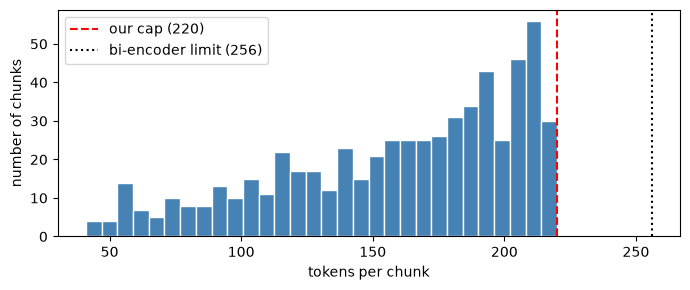


### C0538 | 220 tokens | rules 9.12.4-9.12.4 | pages 87-87
[Netrunner CR v26.03 | 9 Abilities > 9.12 Other Rules and Terminology]
9.12.4. Repeat this process
a. If an ability instructs a player to “repeat this process” without specifying how many times to do so, then that player resolves the ability again, including the instruction to “repeat this process” if it is still applicable.
b. If an ability instructs a player to “repeat this process” a specified number of times, then that player resolves the entire ability, except for the repetition instruction, that many times in a row. The number of repetitions is determined after the first full resolution but before the first repetition, and once the number of repetitions is determined it cannot be changed.
c. Regardless of the number of times an ability is repeated, a checkpoint occurs after each full resolution of the ability’s instructions, before another repetition begins.
d. Each repetition of t

### C0010 | 41 tokens | rules 1.5.1-1.

In [10]:
tokens = [c["n_tokens"] for c in chunks]
print(f"chunks: {len(chunks)} | tokens per chunk: min {min(tokens)}, median {int(np.median(tokens))}, max {max(tokens)}")
print(f"bi-encoder limit: {bi_encoder.max_seq_length} tokens | our cap: {CONFIG['chunk_max_tokens']} | chunks over the cap: {sum(t > CONFIG['chunk_max_tokens'] for t in tokens)}")

# every paragraph of the document must be somewhere in the chunks
all_chunk_text = "\n".join(c["text"] for c in chunks)
missing = [p for u in units for p in u["paras"] if p[:40] not in all_chunk_text]
print("paragraphs missing from the chunks:", len(missing))

print("continuation pieces of long rules:", sum("| continued" in c["text"].split("\n")[0] for c in chunks))
words = r"\b(except|unless|cannot|can't|may not|only if|instead|not allowed|prohibited)\b"
print("chunks with exception / negation wording:", sum(bool(re.search(words, c["text"], re.I)) for c in chunks), "of", len(chunks))

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3))
plt.hist(tokens, bins=30, color="steelblue", edgecolor="white")
plt.axvline(CONFIG["chunk_max_tokens"], color="red", linestyle="--", label="our cap (220)")
plt.axvline(bi_encoder.max_seq_length, color="black", linestyle=":", label="bi-encoder limit (256)")
plt.xlabel("tokens per chunk"); plt.ylabel("number of chunks"); plt.legend(); plt.tight_layout()
plt.savefig(ROOT / "artifacts/figures/chunk_token_hist.png", dpi=120)
plt.show()

# a few chunks to read
by_size = sorted(chunks, key=lambda c: c["n_tokens"])
samples = [by_size[-1], by_size[0]] + random.Random(CONFIG["seed"]).sample(chunks, 5)
for c in samples:
    print(f"\n### {c['chunk_id']} | {c['n_tokens']} tokens | rules {c['rules']} | pages {c['page_start']}-{c['page_end']}")
    print(c["text"][:900])


### 3.2 Freeze

`chunks.jsonl` and `corpus_manifest.json` (document hash, chunk settings, number of chunks, and the SHA-256 of the chunk file) are written once. All later sections load the chunks with `load_corpus()`, which re-checks that hash. This shows that **both pipelines use exactly the same corpus**. A re-run rebuilds identical chunks.

In [11]:
CHUNKS_PATH = ROOT / "artifacts/chunks.jsonl"
MANIFEST_PATH = ROOT / "artifacts/corpus_manifest.json"

chunks_text = "".join(json.dumps(c, ensure_ascii=False) + "\n" for c in chunks)
chunks_sha256 = hashlib.sha256(chunks_text.encode("utf-8")).hexdigest()

if MANIFEST_PATH.exists():                       # on a re-run, the rebuilt chunks must be identical to the frozen ones
    frozen_hash = json.loads(MANIFEST_PATH.read_text())["chunks_sha256"]
    print("rebuilt corpus identical to the frozen one:", frozen_hash == chunks_sha256)

CHUNKS_PATH.write_text(chunks_text, encoding="utf-8")
MANIFEST_PATH.write_text(json.dumps({
    "document": CONFIG["doc"],
    "body_pages": [FIRST_PAGE, LAST_PAGE],
    "chunk_max_tokens": CONFIG["chunk_max_tokens"],
    "chunk_overlap_tokens": CONFIG["chunk_overlap_tokens"],
    "tokenizer": CONFIG["bi_encoder"],
    "n_chunks": len(chunks),
    "chunks_sha256": chunks_sha256,
}, indent=2) + "\n")

def load_corpus():
    """Every later section loads the chunks through this function, so both pipelines use the same corpus."""
    manifest = json.loads(MANIFEST_PATH.read_text())
    file_hash = hashlib.sha256(CHUNKS_PATH.read_bytes()).hexdigest()
    print("chunks.jsonl matches corpus_manifest.json:", file_hash == manifest["chunks_sha256"])
    return [json.loads(line) for line in CHUNKS_PATH.read_text(encoding="utf-8").splitlines()]

corpus = load_corpus()
print(len(corpus), "chunks | sha256:", chunks_sha256)


rebuilt corpus identical to the frozen one: True
chunks.jsonl matches corpus_manifest.json: True
602 chunks | sha256: abc68239ba744f8090f0b65269e7f540f49ac9998622952a44a5707a79d247b0
